In [6]:
import pandas as pd
import numpy as np

# Load the dataset (Fixed the filename here!)
df = pd.read_csv('tmdb_2000_movies_raw.csv')
print(f"Initial shape: {df.shape}")
display(df.head(2))

Initial shape: (2000, 10)


,movie_id,title,release_date,genres,original_language,popularity_score,vote_average,vote_count,overview,runtime
0,969681,Spider-Man: Brand New Day,2026-07-29,"Science Fiction, Action, Adventure",en,710.8120,7.866,2491,Fighting crime full-time as Spider-Man in a wo...,145
1,1204680,Coyote vs. Acme,2026-08-20,"Comedy, Adventure, Family",en,637.0123,7.700,197,After Acme products fail him one too many time...,103


In [7]:
# Rename 'vote_average' to 'rating' for clarity
if 'vote_average' in df.columns:
    df = df.rename(columns={'vote_average': 'rating'})

In [8]:
# Drop any duplicate movies based on their unique ID
df = df.drop_duplicates(subset=['movie_id'], keep='first')
print(f"Shape after removing duplicates: {df.shape}")

Shape after removing duplicates: (1965, 10)


In [9]:
# Drop rows missing crucial info like title or release date
df = df.dropna(subset=['title', 'release_date'])

# Fill missing text fields with 'Unknown' placeholders
df['genres'] = df['genres'].fillna('Unknown')
df['overview'] = df['overview'].fillna('No overview available')

# Handle runtime (replace 0 with NaN, then fill with the median)
if 'runtime' in df.columns:
    df['runtime'] = df['runtime'].replace(0, np.nan)
    df['runtime'] = df['runtime'].fillna(df['runtime'].median()).astype(int)

# Handle certificates
if 'certificate' in df.columns:
    df['certificate'] = df['certificate'].replace('', 'Unknown').fillna('Unknown')
    
print("Missing values handled.")

Missing values handled.


In [10]:
# Map ISO language shortcuts (e.g., 'en') to full names (e.g., 'English')
language_map = {
    'en': 'English', 'ja': 'Japanese', 'fr': 'French', 'es': 'Spanish',
    'ko': 'Korean', 'hi': 'Hindi', 'it': 'Italian', 'zh': 'Chinese',
    'cn': 'Chinese', 'de': 'German', 'ru': 'Russian', 'pt': 'Portuguese',
    'ta': 'Tamil', 'te': 'Telugu', 'sv': 'Swedish', 'da': 'Danish',
    'nl': 'Dutch', 'tr': 'Turkish', 'id': 'Indonesian', 'pl': 'Polish',
    'th': 'Thai', 'ar': 'Arabic', 'no': 'Norwegian', 'fi': 'Finnish'
}

# Apply map; if a shortcut isn't in the list, keep it capitalized
df['original_language'] = df['original_language'].map(language_map).fillna(df['original_language'].str.upper())
print("Languages mapped successfully.")

Languages mapped successfully.


In [11]:
# Convert release_date to a proper datetime object
df['release_date'] = pd.to_datetime(df['release_date'])

# Extract Year and Month Name for better dashboard visualizations
df['release_year'] = df['release_date'].dt.year.astype(int)
df['release_month'] = df['release_date'].dt.month_name() # e.g., 'January'

print(df[['release_date', 'release_year', 'release_month']].head(3))

  release_date  release_year release_month
0   2026-07-29          2026          July
1   2026-08-20          2026        August
2   2026-07-15          2026          July


In [12]:
# Clean and round numerical data for presentation
df['rating'] = df['rating'].astype(float).round(1) 
df['popularity_score'] = df['popularity_score'].astype(float).round(2)
df['vote_count'] = df['vote_count'].astype(int)

# Reorder columns logically
cols = ['movie_id', 'title', 'release_year', 'release_month', 'release_date', 'genres', 'original_language']

if 'runtime' in df.columns and 'certificate' in df.columns:
    cols.extend(['runtime', 'certificate'])
    
cols.extend(['popularity_score', 'rating', 'vote_count', 'overview'])

df = df[cols]
print("Columns reordered and data types formatted.")

Columns reordered and data types formatted.


In [13]:
# View the total number of rows and columns, plus data types
df.info()

# Display the first 10 rows of your cleaned data
display(df.head(10))

<class 'pandas.DataFrame'>
Index: 1964 entries, 0 to 1999
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   movie_id           1964 non-null   int64         
 1   title              1964 non-null   str           
 2   release_year       1964 non-null   int64         
 3   release_month      1964 non-null   str           
 4   release_date       1964 non-null   datetime64[us]
 5   genres             1964 non-null   str           
 6   original_language  1964 non-null   str           
 7   popularity_score   1964 non-null   float64       
 8   rating             1964 non-null   float64       
 9   vote_count         1964 non-null   int64         
 10  overview           1964 non-null   str           
dtypes: datetime64[us](1), float64(2), int64(3), str(5)
memory usage: 796.9 KB


,movie_id,title,release_year,release_month,release_date,genres,original_language,popularity_score,rating,vote_count,overview
0,969681,Spider-Man: Brand New Day,2026,July,2026-07-29,"Science Fiction, Action, Adventure",English,710.81,7.9,2491,Fighting crime full-time as Spider-Man in a wo...
1,1204680,Coyote vs. Acme,2026,August,2026-08-20,"Comedy, Adventure, Family",English,637.01,7.7,197,After Acme products fail him one too many time...
2,1368337,The Odyssey,2026,July,2026-07-15,"Adventure, Action, Fantasy",English,500.15,8.0,3529,"Odysseus, the legendary King of Ithaca, embark..."
3,1288445,Mutiny,2026,August,2026-08-19,"Action, Thriller",English,436.81,6.4,310,After witnessing his billionaire boss' murder ...
4,1386315,The Runner,2026,September,2026-09-03,"Thriller, Action",English,325.55,6.7,304,"Maia Marten, a brilliant London lawyer, has he..."
5,1375646,Colony,2026,May,2026-05-21,"Action, Horror, Science Fiction",Korean,318.18,8.1,705,Professor Se-jeong is thrust into a bloody nig...
6,1285366,Shape of My Heart,2024,July,2024-07-06,Romance,Japanese,241.32,5.2,5,"A romance about a man and a woman who, due to ..."
7,1393326,Ghost in the Cell,2026,April,2026-04-16,"Horror, Comedy, Thriller",Indonesian,227.33,7.1,46,"In a notorious prison, an invisible force begi..."
8,1137844,Mayday,2026,September,2026-09-03,"Action, Comedy",English,226.62,8.0,258,When a U.S. Navy pilot on a top-secret mission...
9,1339713,Obsession,2026,May,2026-05-13,"Horror, Thriller",English,225.73,8.2,5352,"After breaking the mysterious ""One Wish Willow..."


In [14]:
# Save the final cleaned dataset to your computer
df.to_csv('tmdb_movies_cleaned_final.csv', index=False)

In [15]:
# 3. Exploratory Data Analysis & Visualization

In [16]:
# Import our basic visualization libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Make all charts look clean and professional
sns.set_theme(style="whitegrid")

# Load the cleaned dataset we made in Task 2
df = pd.read_csv('tmdb_movies_cleaned_final.csv')

# Look at the basic math (mean, min, max) for our numbers
print("Basic Statistical Summary:")
display(df.describe().round(2))

Basic Statistical Summary:


,movie_id,release_year,popularity_score,rating,vote_count
count,1964.00,1964.00,1964.00,1964.00,1964.00
mean,479887.18,2009.66,23.20,6.69,5681.14
std,528160.73,17.32,33.45,1.66,6158.58
min,11.00,1929.00,10.80,0.00,0.00
25%,10130.75,2002.00,13.24,6.40,719.00
50%,290554.50,2015.00,16.20,7.00,4097.00
75%,918549.75,2024.00,22.25,7.50,8134.00
max,1753010.00,2028.00,710.81,10.00,41068.00


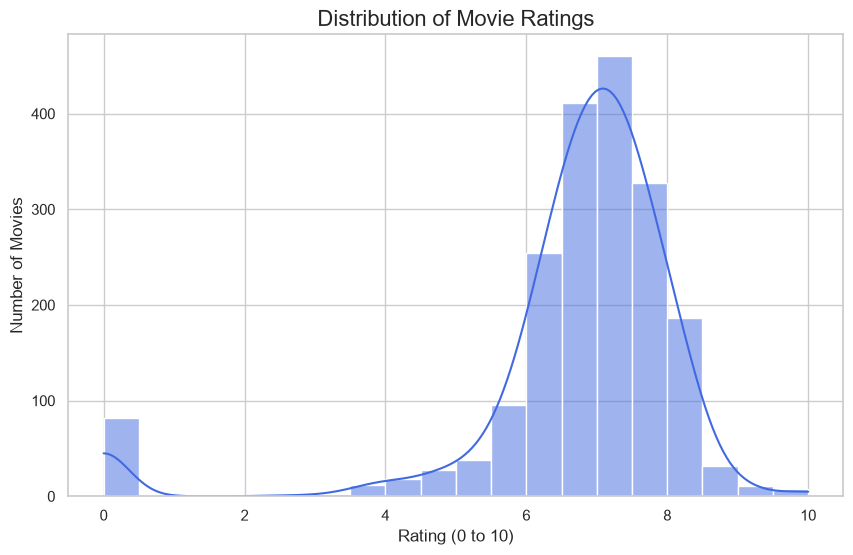

In [17]:
# Set the size of the chart
plt.figure(figsize=(10, 6))

# Create a simple histogram of the ratings
sns.histplot(df['rating'], bins=20, color='royalblue', kde=True)

# Add clear labels so the business team understands it
plt.title('Distribution of Movie Ratings', fontsize=16)
plt.xlabel('Rating (0 to 10)', fontsize=12)
plt.ylabel('Number of Movies', fontsize=12)

# Show the chart
plt.show()

C:\Users\dell\AppData\Local\Temp\ipykernel_13848\188750452.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_10_genres.values, y=top_10_genres.index, palette='viridis')


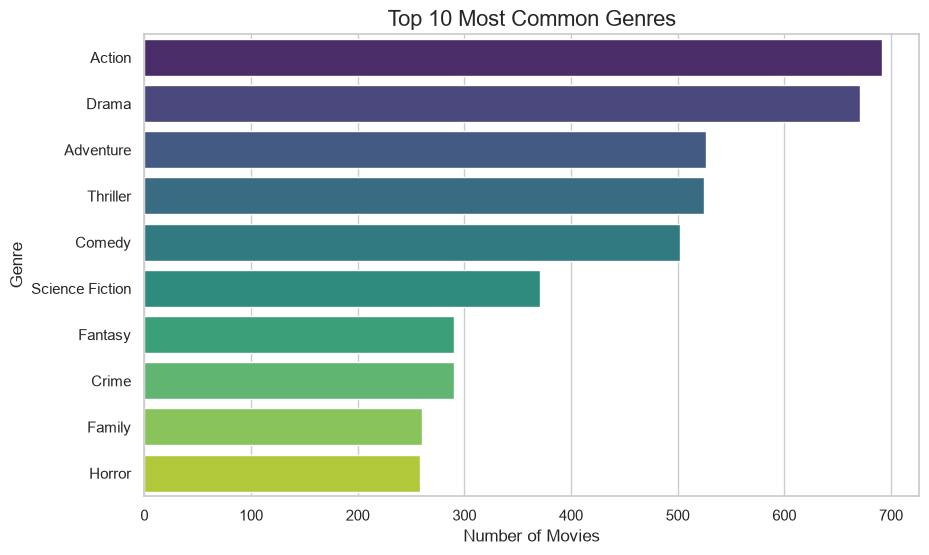

In [18]:
# 1. Drop movies with unknown genres just for this chart
genre_data = df[df['genres'] != 'Unknown'].copy()

# 2. Split the comma-separated genres and count them
# (We use a simple string split and explode to separate them into their own rows)
genre_counts = genre_data.assign(genres=genre_data['genres'].str.split(', ')).explode('genres')
top_10_genres = genre_counts['genres'].value_counts().head(10)

# 3. Create a horizontal bar chart
plt.figure(figsize=(10, 6))
sns.barplot(x=top_10_genres.values, y=top_10_genres.index, palette='viridis')

plt.title('Top 10 Most Common Genres', fontsize=16)
plt.xlabel('Number of Movies', fontsize=12)
plt.ylabel('Genre', fontsize=12)

plt.show()

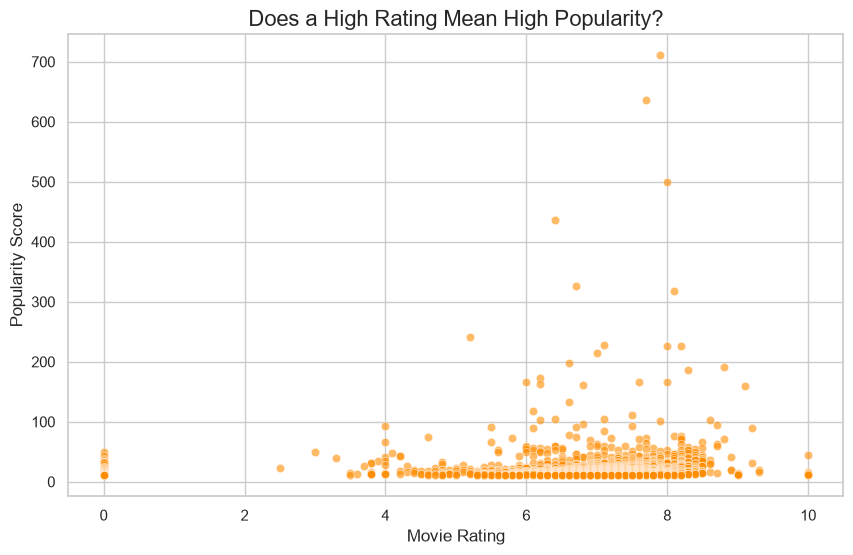

In [19]:
plt.figure(figsize=(10, 6))

# Plot rating on the X axis, and popularity on the Y axis
sns.scatterplot(data=df, x='rating', y='popularity_score', color='darkorange', alpha=0.6)

plt.title('Does a High Rating Mean High Popularity?', fontsize=16)
plt.xlabel('Movie Rating', fontsize=12)
plt.ylabel('Popularity Score', fontsize=12)

plt.show()

C:\Users\dell\AppData\Local\Temp\ipykernel_13848\1140523352.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='release_month', order=month_order, palette='magma')


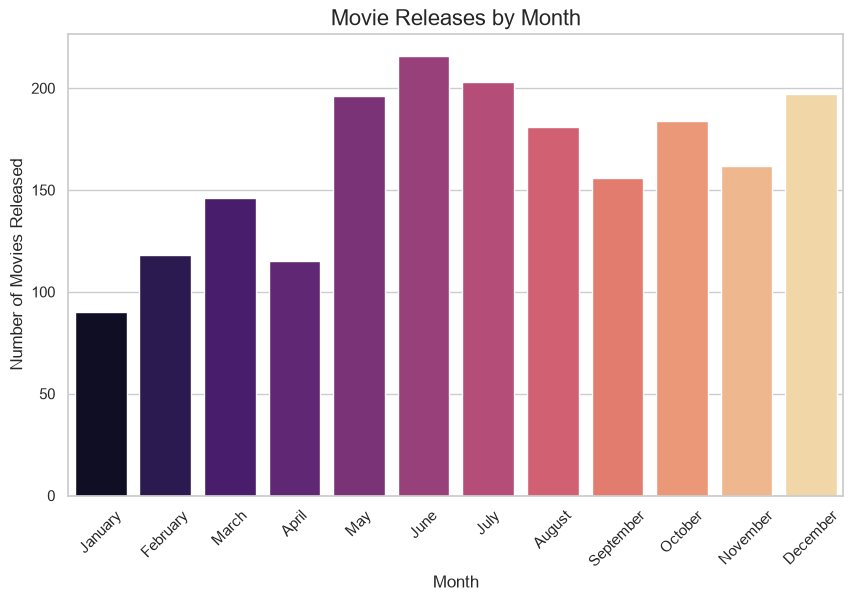

In [20]:
plt.figure(figsize=(10, 6))

# Order the months chronologically so the chart makes sense
month_order = ['January', 'February', 'March', 'April', 'May', 'June', 
               'July', 'August', 'September', 'October', 'November', 'December']

# Count how many movies were released in each month
sns.countplot(data=df, x='release_month', order=month_order, palette='magma')

plt.title('Movie Releases by Month', fontsize=16)
plt.xlabel('Month', fontsize=12)
plt.ylabel('Number of Movies Released', fontsize=12)

# Rotate the month names so they don't overlap
plt.xticks(rotation=45)

plt.show()

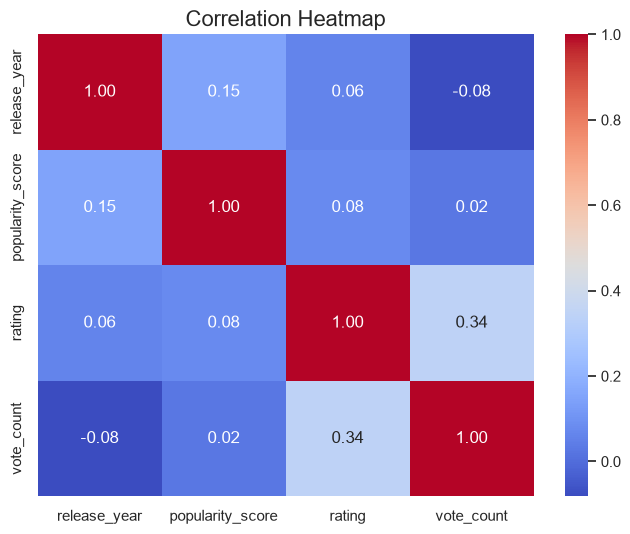

In [21]:
plt.figure(figsize=(8, 6))

# Pick only our number columns
num_data = df[['release_year', 'popularity_score', 'rating', 'vote_count']]

# Calculate how closely related they are to each other
correlation_math = num_data.corr()

# Draw the heatmap
sns.heatmap(correlation_math, annot=True, cmap='coolwarm', fmt=".2f")

plt.title('Correlation Heatmap', fontsize=16)
plt.show()

In [22]:
# Model Building & Evaluation

In [23]:
# Prepare the Data for Machine Learning

In [24]:
# Import Machine Learning tools from scikit-learn
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Create our Target Variable (The thing we want to predict)
# Let's define a "Hit" movie as having a rating of 7.0 or higher.
# This creates a new column with 1 for Hit, and 0 for Average/Flop.
df['is_hit'] = (df['rating'] >= 7.0).astype(int)

# 2. Pick our Features (The clues the machine will use to guess)
# We will keep it simple and use our strong numerical columns
features = ['popularity_score', 'vote_count', 'release_year']

X = df[features]  # The clues
y = df['is_hit']  # The answer key

print("Data is ready for the machine!")
print(f"Total Hit Movies: {y.sum()}")
print(f"Total Average/Flop Movies: {len(y) - y.sum()}")

Data is ready for the machine!
Total Hit Movies: 1024
Total Average/Flop Movies: 940


In [25]:
# Split Data into Training and Testing

In [26]:
# Split the data (80% for training, 20% for testing)
# random_state=42 ensures we get the same split every time we run this code
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training on {len(X_train)} movies...")
print(f"Testing on {len(X_test)} movies...")

Training on 1571 movies...
Testing on 393 movies...


In [27]:
# Train the Machine Learning Model

In [28]:
# Create the Random Forest model
# We use 100 'trees' to make the decision
model = RandomForestClassifier(n_estimators=100, random_state=42)

# Train the model using our 80% training data
model.fit(X_train, y_train)

print("Model training complete! The machine has learned the patterns.")

Model training complete! The machine has learned the patterns.


In [29]:
# Test the Model and See Our Score

In [30]:
# Ask the model to predict if the test movies are hits or flops
predictions = model.predict(X_test)

# Calculate the accuracy score
accuracy = accuracy_score(y_test, predictions)
print(f"Model Accuracy: {accuracy * 100:.2f}%")
print("-" * 50)

# Print a detailed report card (Precision, Recall, F1-Score)
print("Detailed Report Card:")
print(classification_report(y_test, predictions, target_names=['Flop/Average', 'Hit']))

Model Accuracy: 67.94%
--------------------------------------------------
Detailed Report Card:
              precision    recall  f1-score   support

Flop/Average       0.69      0.64      0.66       195
         Hit       0.67      0.72      0.69       198

    accuracy                           0.68       393
   macro avg       0.68      0.68      0.68       393
weighted avg       0.68      0.68      0.68       393



In [31]:
# Visualize the Results (Confusion Matrix)

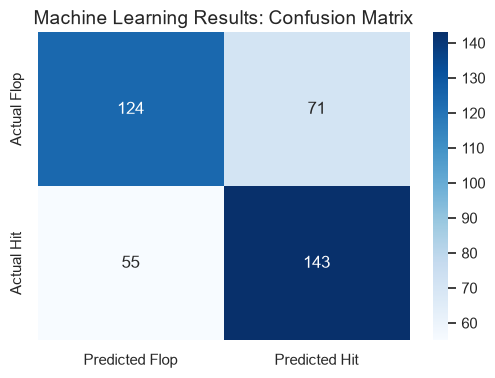

In [32]:
# Create the Confusion Matrix
cm = confusion_matrix(y_test, predictions)

# Draw it nicely using Seaborn
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Predicted Flop', 'Predicted Hit'], 
            yticklabels=['Actual Flop', 'Actual Hit'])

plt.title('Machine Learning Results: Confusion Matrix', fontsize=14)
plt.show()

In [33]:
# What Makes a Hit Movie? (Feature Importance)

C:\Users\dell\AppData\Local\Temp\ipykernel_13848\4153947230.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importance_scores, y=features, palette='rocket')


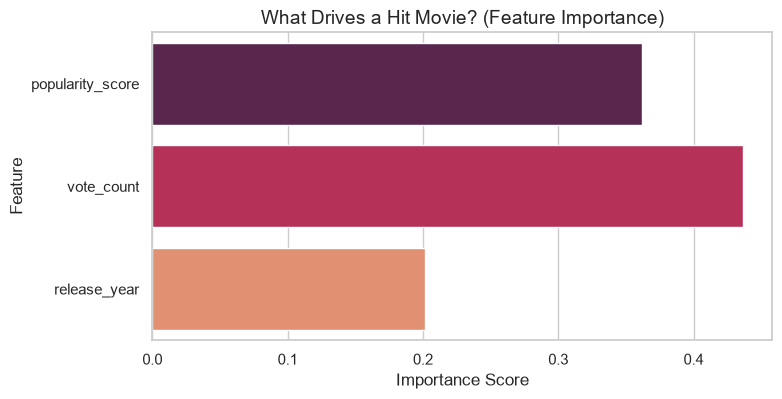

In [34]:
# Get the importance scores from the model
importance_scores = model.feature_importances_

# Create a simple bar chart to show the winner
plt.figure(figsize=(8, 4))
sns.barplot(x=importance_scores, y=features, palette='rocket')

plt.title('What Drives a Hit Movie? (Feature Importance)', fontsize=14)
plt.xlabel('Importance Score', fontsize=12)
plt.ylabel('Feature', fontsize=12)
plt.show()

In [35]:
# The ROC Curve & AUC Score

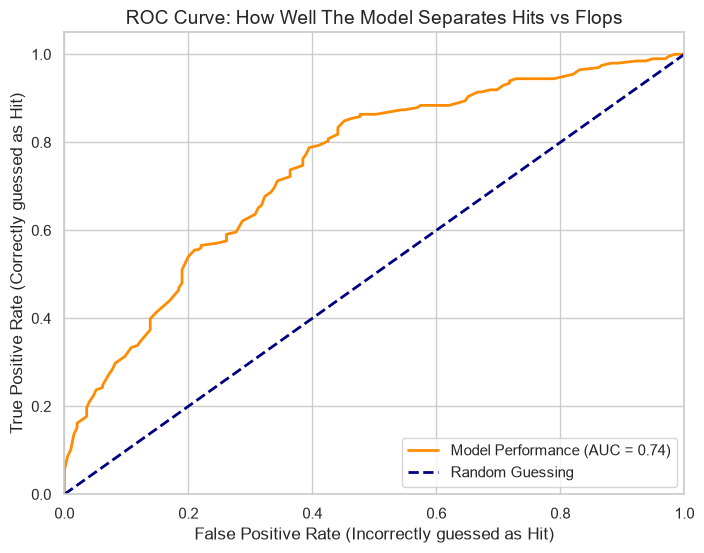

In [36]:
from sklearn.metrics import roc_curve, auc

# Get the machine's confidence percentages (probabilities) for the test data
y_pred_prob = model.predict_proba(X_test)[:, 1]

# Calculate the curve points
fpr, tpr, thresholds = roc_curve(y_test, y_pred_prob)
roc_auc = auc(fpr, tpr)

# Draw the ROC Curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'Model Performance (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Guessing')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (Incorrectly guessed as Hit)', fontsize=12)
plt.ylabel('True Positive Rate (Correctly guessed as Hit)', fontsize=12)
plt.title('ROC Curve: How Well The Model Separates Hits vs Flops', fontsize=14)
plt.legend(loc="lower right")
plt.show()

In [37]:
# Prediction Confidence Distribution

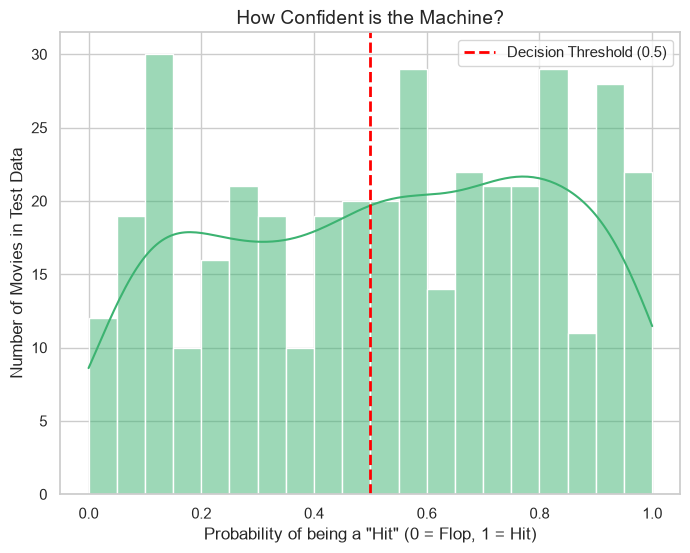

In [38]:
plt.figure(figsize=(8, 6))

# Plot the distribution of the model's confidence scores
sns.histplot(y_pred_prob, bins=20, kde=True, color='mediumseagreen')

plt.title('How Confident is the Machine?', fontsize=14)
plt.xlabel('Probability of being a "Hit" (0 = Flop, 1 = Hit)', fontsize=12)
plt.ylabel('Number of Movies in Test Data', fontsize=12)

# Draw a line at 0.5 (the threshold where the machine decides Hit vs Flop)
plt.axvline(0.5, color='red', linestyle='dashed', linewidth=2, label='Decision Threshold (0.5)')
plt.legend()
plt.show()